# Lab Assignment: English-to-German Machine Translation with a Transformer

**Objective:**
The goal of this assignment is to fine-tune a pre-trained **Transformer** model for machine translation. You will load a dataset, fine-tune the model, and evaluate it using the BLEU score.

You will also compare your new model's performance and architecture against a previous **LSTM-based** model, and visualize the **self-attention** and **cross-attention** mechanisms that make the Transformer so powerful.


## Part 1: Setup and Environment

First, install all the necessary libraries.

In [1]:
# Install everything (restart the runtime if Colab asks you to)
!pip install -q -U transformers datasets evaluate sacrebleu sentencepiece sacremoses accelerate bertviz

import torch
print("GPU available:", torch.cuda.is_available())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 70.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 90.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 123.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 8.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not cu

## Part 2: Data Loading and Pre-processing

### 1. Load the Dataset
We have to use previously provided dataset, which contains parallel sentences for English-to-German translation.

In [2]:
import os, csv, zipfile
os.environ["USE_TF"] = "0"          # keep transformers from touching TensorFlow/Keras
import numpy as np
import pandas as pd
from datasets import Dataset, DatasetDict

# ---- PATHS (Colab) ----
ZIP_PATH = '/content/deu-eng.zip'        # the zip you uploaded in the Files panel
DATA_DIR = '/content/deu_data'           # where we unzip it
DATA_PATH = f'{DATA_DIR}/deu.txt'

if not os.path.exists(DATA_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(DATA_DIR)
print("deu.txt found:", os.path.exists(DATA_PATH))

# deu.txt is tab separated: English <tab> German <tab> attribution
df = pd.read_csv(DATA_PATH, sep='\t', header=None, usecols=[0, 1],
                 names=['en', 'de'], quoting=csv.QUOTE_NONE, encoding='utf-8')
print("Total sentence pairs in file:", len(df))

# The file is sorted from short to long sentences, so take a RANDOM subset
# (the full 270k+ pairs would take far too long to fine-tune in Colab).
NUM_PAIRS = 20000
df = df.sample(n=NUM_PAIRS, random_state=42).reset_index(drop=True)

# 80% train / 10% validation / 10% test
full = Dataset.from_pandas(df)
split = full.train_test_split(test_size=0.2, seed=42)
val_test = split['test'].train_test_split(test_size=0.5, seed=42)

raw_datasets = DatasetDict({
    'train': split['train'],
    'validation': val_test['train'],
    'test': val_test['test'],
})
print(raw_datasets)
print(raw_datasets['train'][0])


deu.txt found: True
Total sentence pairs in file: 331266
DatasetDict({
    train: Dataset({
        features: ['en', 'de'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['en', 'de'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['en', 'de'],
        num_rows: 2000
    })
})
{'en': 'Everybody would like to believe dreams can come true.', 'de': 'Jeder möchte gerne glauben, daß Träume wahr werden können.'}


### 2. Load Tokenizer and Model
We will use a pre-trained model from the Helsinki-NLP group, `opus-mt-en-de`, which is a lightweight and efficient Transformer specifically designed for English-to-German translation.

In [3]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_checkpoint = "Helsinki-NLP/opus-mt-en-de"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

print("Parameters:", round(model.num_parameters() / 1e6, 1), "M")


config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/768k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/797k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  298MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Parameters: 74.4 M


### 3. Pre-processing Function
We must tokenize both the English (input) and German (target) sentences. For seq2seq models, the tokenized target sentences are assigned to the `labels` key.

In [4]:
max_length = 128

def preprocess_function(examples):
    # English -> input_ids, German -> labels (via text_target)
    model_inputs = tokenizer(examples["en"], text_target=examples["de"],
                             max_length=max_length, truncation=True)
    return model_inputs


### 4. Apply Pre-processing
Use the `.map()` function to apply this tokenization to the entire dataset.

In [5]:
tokenized_datasets = raw_datasets.map(
    preprocess_function,
    batched=True,
    remove_columns=raw_datasets["train"].column_names,
)
print(tokenized_datasets)


Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2000
    })
})


## Part 3: Fine-Tuning the Model

### 1. Define Evaluation Metric (BLEU)
Machine translation is evaluated using the **BLEU score**. You can load the `sacrebleu` metric and create a `compute_metrics` function to use during training.

In [6]:
import evaluate

metric = evaluate.load("sacrebleu")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # -100 (ignored label positions) can't be decoded, swap for the pad id
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [p.strip() for p in decoded_preds]
    decoded_labels = [[l.strip()] for l in decoded_labels]   # sacrebleu wants a list of references

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    gen_len = np.mean([np.count_nonzero(p != tokenizer.pad_token_id) for p in preds])
    return {"bleu": round(result["score"], 2), "gen_len": round(float(gen_len), 2)}


### 2. Configure Training
We will use the `Seq2SeqTrainer` and `Seq2SeqTrainingArguments` classes to manage the fine-tuning process.

In [7]:
from transformers import (DataCollatorForSeq2Seq, Seq2SeqTrainingArguments,
                          Seq2SeqTrainer)

# ---- PATH where the fine-tuned model will be saved ----
OUTPUT_DIR = '/content/opus-mt-en-de-finetuned'

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=3,
    predict_with_generate=True,
    generation_max_length=max_length,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)


### 3. Start Training


In [8]:
train_result = trainer.train()

# save the final model + tokenizer so we can reload them later (pipeline, attention plots)
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print("Saved to:", OUTPUT_DIR)


Epoch,Training Loss,Validation Loss,Bleu,Gen Len
1,0.676469,0.624048,49.140000,9.310000
2,0.579512,0.622489,48.960000,9.320000
3,0.510140,0.624494,49.170000,9.320000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /content/opus-mt-en-de-finetuned


### 4. Evaluate the Model
After training, run the final evaluation on the test set.

In [9]:
test_results = trainer.evaluate(tokenized_datasets["test"], metric_key_prefix="test")
print(test_results)
print("\nTest BLEU:", test_results["test_bleu"])


Training Loss,Validation Loss,Epoch,Bleu,Gen Len
0.510140,0.635797,3,49.640000,9.330000


{'test_loss': 0.635797381401062, 'test_bleu': 49.64, 'test_gen_len': 9.33}

Test BLEU: 49.64


## Part 4: Inference (Testing the Translator)

Now use your fine-tuned model to translate new sentences using the `pipeline` utility.

In [12]:
# Test with new sentences
text1 = "Hello, how are you doing today?"
text2 = "The transformer model is a powerful architecture for NLP."
text3 = "This assignment is for my machine learning lab."

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

# Load the fine-tuned model and tokenizer directly
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
translator_tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR)
translator_model = AutoModelForSeq2SeqLM.from_pretrained(OUTPUT_DIR).to(device)

def translate(text):
    inputs = translator_tokenizer(text, return_tensors="pt", max_length=128, truncation=True).to(device)
    with torch.no_grad():
        generated_tokens = translator_model.generate(**inputs, max_length=128)
    return translator_tokenizer.decode(generated_tokens[0], skip_special_tokens=True)

for t in [text1, text2, text3]:
    print("EN:", t)
    print("DE:", translate(t))
    print()


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

EN: Hello, how are you doing today?
DE: Hallo, wie geht es dir heute?

EN: The transformer model is a powerful architecture for NLP.
DE: Das Transformatorenmodell ist eine leistungsstarke Architektur für NLP.

EN: This assignment is for my machine learning lab.
DE: Diese Aufgabe ist für mein Maschinenlernlabor bestimmt.



## Part 5: Comparative Analysis (Transformer vs. LSTM)

In this section, you will directly compare the output of your new Transformer model with the LSTM-based model from your previous lab.

### 5.1. Test Sentences
Here is a list of 10 English sentences varying in length and complexity.

In [13]:
test_sentences = [
    # 1. Simple sentence
    "The cat sat on the mat.",

    # 2. Longer sentence
    "I am going to the library to read a book.",

    # 3. Question
    "What is your favorite color?",

    # 4. Long-range dependency
    "The man who lives down the street just bought a new car.",

    # 5. Figurative language (often difficult)
    "It's raining cats and dogs outside.",

    # 6. Technical term
    "The machine learning model was trained on a large dataset.",

    # 7. Command
    "Please close the door when you leave.",

    # 8. Classic test sentence
    "The quick brown fox jumps over the lazy dog.",

    # 9. Negation
    "He did not want to go to the party.",

    # 10. Future tense
    "We will travel to Germany next summer."
]


### 5.2. Translation and Comparison

**Your Task:**
1.  **Generate Transformer Translations:** Run the code cell above to get the Transformer's translations.
2.  **Generate LSTM Translations:** Load your saved LSTM model and tokenizer from the previous lab. Use it to translate the same 10 above `test_sentences`.
3.  **Create Comparison Table:** **Double-click this text cell** to edit it. Fill in the table below with your models' outputs.

| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 2 | I am going to the library... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 3 | What is your favorite color?| *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 4 | The man who lives down... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 5 | It's raining cats and dogs... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 6 | The machine learning model...| *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 7 | Please close the door... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 8 | The quick brown fox... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 9 | He did not want to go... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |
| 10| We will travel to Germany... | *... (Your LSTM's output)* | *... (Your Transformer's output)* |

In [16]:
# ---- 1) Transformer translations of the 10 test sentences ----
transformer_outputs = [translate(s) for s in test_sentences]

for en, de in zip(test_sentences, transformer_outputs):
    print(en, "->", de)


The cat sat on the mat. -> Die Katze saß auf der Matte.
I am going to the library to read a book. -> Ich gehe in die Bibliothek, um ein Buch zu lesen.
What is your favorite color? -> Was ist deine Lieblingsfarbe?
The man who lives down the street just bought a new car. -> Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft.
It's raining cats and dogs outside. -> Draußen regnet es Katzen und Hunde.
The machine learning model was trained on a large dataset. -> Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert.
Please close the door when you leave. -> Bitte schließen Sie die Tür, wenn Sie gehen.
The quick brown fox jumps over the lazy dog. -> Der schnelle braune Fuchs springt über den faulen Hund.
He did not want to go to the party. -> Er wollte nicht auf die Party gehen.
We will travel to Germany next summer. -> Wir werden im nächsten Sommer nach Deutschland reisen.


In [17]:
# ---- 2) LSTM translations (model from the previous lab) ----
import tensorflow as tf
try:
    tf.config.set_visible_devices([], 'GPU')   # run the small LSTM on CPU so it doesn't fight PyTorch for GPU memory
except Exception as e:
    print(e)
from tensorflow import keras
from tensorflow.keras.layers import Input

# ---- PATHS / SETTINGS from Lab 8 ----
LSTM_MODEL_PATH = '/content/s2s_eng_ger.h5'   # upload the file saved in Lab 8 to the Files panel
LSTM_DATA_PATH = DATA_PATH                    # same deu.txt
LSTM_NUM_SAMPLES = 10000                      # checked against your s2s_eng_ger.h5: 70 input / 84 output chars = first 10000 lines

# rebuild the character vocab exactly like Lab 8
input_texts, target_texts = [], []
input_characters, target_characters = set(), set()
with open(LSTM_DATA_PATH, 'r', encoding='utf-8') as f:
    lines = f.read().split('\n')
for line in lines[: min(LSTM_NUM_SAMPLES, len(lines) - 1)]:
    parts = line.split('\t')
    it, tt = parts[0], '\t' + parts[1] + '\n'
    input_texts.append(it)
    target_texts.append(tt)
    input_characters.update(it)
    target_characters.update(tt)
input_characters = sorted(input_characters)
target_characters = sorted(target_characters)

num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max(len(t) for t in input_texts)
max_decoder_seq_length = max(len(t) for t in target_texts)
input_token_index = {c: i for i, c in enumerate(input_characters)}
target_token_index = {c: i for i, c in enumerate(target_characters)}
reverse_target_char_index = {i: c for c, i in target_token_index.items()}

# load the trained LSTM and rebuild the inference encoder/decoder
lstm_model = keras.models.load_model(LSTM_MODEL_PATH, compile=False)

model_enc_tokens = lstm_model.input[0].shape[-1]
model_dec_tokens = lstm_model.input[1].shape[-1]
assert (model_enc_tokens, model_dec_tokens) == (num_encoder_tokens, num_decoder_tokens), (
    f"Vocab mismatch: model expects {model_enc_tokens}/{model_dec_tokens} chars but the data gives "
    f"{num_encoder_tokens}/{num_decoder_tokens}. Change LSTM_NUM_SAMPLES to what you used in Lab 8.")

lstm_layers = [l for l in lstm_model.layers if isinstance(l, keras.layers.LSTM)]
enc_lstm = [l for l in lstm_layers if not l.return_sequences][0]
dec_lstm = [l for l in lstm_layers if l.return_sequences][0]
dec_dense = [l for l in lstm_model.layers if isinstance(l, keras.layers.Dense)][0]
latent_dim = enc_lstm.units

_, enc_h, enc_c = enc_lstm.output
lstm_encoder_model = keras.Model(lstm_model.input[0], [enc_h, enc_c])

dec_inputs = lstm_model.input[1]
# Fix: Explicitly specify unique names to prevent Keras layer name collisions
state_in_h = Input(shape=(latent_dim,), name='decoder_state_h_input')
state_in_c = Input(shape=(latent_dim,), name='decoder_state_c_input')
dec_out, dec_h, dec_c = dec_lstm(dec_inputs, initial_state=[state_in_h, state_in_c])
dec_out = dec_dense(dec_out)
lstm_decoder_model = keras.Model([dec_inputs, state_in_h, state_in_c], [dec_out, dec_h, dec_c])


def lstm_encode_input(text):
    width = max(len(text), max_encoder_seq_length)
    x = np.zeros((1, width, num_encoder_tokens), dtype="float32")
    for t, ch in enumerate(text):
        if ch in input_token_index:           # characters the LSTM never saw are skipped
            x[0, t, input_token_index[ch]] = 1.0
    x[0, len(text):, input_token_index[' ']] = 1.0
    return x


def lstm_translate(text):
    states = lstm_encoder_model.predict(lstm_encode_input(text), verbose=0)
    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    target_seq[0, 0, target_token_index['\t']] = 1.0
    out = ""
    while True:
        probs, h, c = lstm_decoder_model.predict([target_seq] + states, verbose=0)
        idx = int(np.argmax(probs[0, -1, :]))
        ch = reverse_target_char_index[idx]
        if ch == '\n' or len(out) >= max_decoder_seq_length:
            break
        out += ch
        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
        target_seq[0, 0, idx] = 1.0
        states = [h, c]
    return out


lstm_outputs = [lstm_translate(s) for s in test_sentences]
for en, de in zip(test_sentences, lstm_outputs):
    print(en, "->", de)


The cat sat on the mat. -> Du bist schüchtern.
I am going to the library to read a book. -> Ich bin nicht zu schwach.
What is your favorite color? -> Wer ist das Tom?
The man who lives down the street just bought a new car. -> Ich schöse Tom angerafen.
It's raining cats and dogs outside. -> Ich bin das Seit.
The machine learning model was trained on a large dataset. -> Ich schöse das Tom geschlafen.
Please close the door when you leave. -> Sei drankte schnellen?
The quick brown fox jumps over the lazy dog. -> Ich schöse Tom an.
He did not want to go to the party. -> Ess ist schlecht an.
We will travel to Germany next summer. -> Ess war nicht schwach.


In [18]:
# ---- 3) Comparison table (copy the printed text into the markdown cell above) ----
rows = ["| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |",
        "|---|---|---|---|"]
for i, (en, l, t) in enumerate(zip(test_sentences, lstm_outputs, transformer_outputs), 1):
    rows.append(f"| {i} | {en} | {l} | {t} |")
print("\n".join(rows))

pd.DataFrame({"English": test_sentences, "LSTM": lstm_outputs, "Transformer": transformer_outputs})


| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | Du bist schüchtern. | Die Katze saß auf der Matte. |
| 2 | I am going to the library to read a book. | Ich bin nicht zu schwach. | Ich gehe in die Bibliothek, um ein Buch zu lesen. |
| 3 | What is your favorite color? | Wer ist das Tom? | Was ist deine Lieblingsfarbe? |
| 4 | The man who lives down the street just bought a new car. | Ich schöse Tom angerafen. | Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft. |
| 5 | It's raining cats and dogs outside. | Ich bin das Seit. | Draußen regnet es Katzen und Hunde. |
| 6 | The machine learning model was trained on a large dataset. | Ich schöse das Tom geschlafen. | Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert. |
| 7 | Please close the door when you leave. | Sei drankte schnellen? | Bitte schließen Sie die Tür, wenn Sie gehen. |
| 8 | The qu

,English,LSTM,Transformer
0,The cat sat on the mat.,Du bist schüchtern.,Die Katze saß auf der Matte.
1,I am going to the library to read a book.,Ich bin nicht zu schwach.,"Ich gehe in die Bibliothek, um ein Buch zu lesen."
2,What is your favorite color?,Wer ist das Tom?,Was ist deine Lieblingsfarbe?
3,The man who lives down the street just bought ...,Ich schöse Tom angerafen.,"Der Mann, der die Straße runter wohnt, hat ger..."
4,It's raining cats and dogs outside.,Ich bin das Seit.,Draußen regnet es Katzen und Hunde.
5,The machine learning model was trained on a la...,Ich schöse das Tom geschlafen.,Das Modell des maschinellen Lernens wurde auf ...
6,Please close the door when you leave.,Sei drankte schnellen?,"Bitte schließen Sie die Tür, wenn Sie gehen."
7,The quick brown fox jumps over the lazy dog.,Ich schöse Tom an.,Der schnelle braune Fuchs springt über den fau...
8,He did not want to go to the party.,Ess ist schlecht an.,Er wollte nicht auf die Party gehen.
9,We will travel to Germany next summer.,Ess war nicht schwach.,Wir werden im nächsten Sommer nach Deutschland...


## Part 6: Visualizing Attention Mechanisms

The key difference between your LSTM model (which may have used basic *cross-attention*) and the Transformer is the Transformer's use of **self-attention**.

* **Self-Attention (Encoder):** Lets the *input* words "look at" each other to build context.
* **Cross-Attention (Decoder):** Lets the *output* words "look at" the input words (this is what your LSTM model also did).

### 1. Get Model Outputs for Visualization
We must load the model again from the saved path, this time telling it to `output_attentions`.

In [19]:
import matplotlib.pyplot as plt
from bertviz import head_view

# reload the fine-tuned model with attentions switched on
# ("eager" attention is needed, the fast default implementation doesn't return attention weights)
attn_model = AutoModelForSeq2SeqLM.from_pretrained(
    OUTPUT_DIR, output_attentions=True, attn_implementation="eager")
attn_tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR)
attn_model.eval()

sentence = test_sentences[3]     # "The man who lives down the street just bought a new car."

enc = attn_tokenizer(sentence, return_tensors="pt")
with torch.no_grad():
    generated = attn_model.generate(**enc, max_length=128)    # starts with the decoder start token

with torch.no_grad():
    outputs = attn_model(input_ids=enc["input_ids"],
                         attention_mask=enc["attention_mask"],
                         decoder_input_ids=generated)

encoder_tokens = attn_tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
decoder_tokens = attn_tokenizer.convert_ids_to_tokens(generated[0])

print("English:", sentence)
print("German :", attn_tokenizer.decode(generated[0], skip_special_tokens=True))
print("encoder layers:", len(outputs.encoder_attentions), "| heads:", outputs.encoder_attentions[0].shape[1])


def plot_heatmap(matrix, xlabels, ylabels, title):
    plt.figure(figsize=(7, 6))
    plt.imshow(matrix, cmap="viridis")
    plt.xticks(range(len(xlabels)), xlabels, rotation=90)
    plt.yticks(range(len(ylabels)), ylabels)
    plt.title(title)
    plt.colorbar()
    plt.tight_layout()
    plt.show()


[transformers] The following generation flags are not valid and may be ignored: ['output_attentions']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

English: The man who lives down the street just bought a new car.
German : Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft.
encoder layers: 6 | heads: 8


### 2. Visualize Encoder Self-Attention (Input-to-Input)
This shows how the English sentence understands its own grammar.

**Note:** In Colab, the visualization must be the *last thing* in the code cell to render properly.

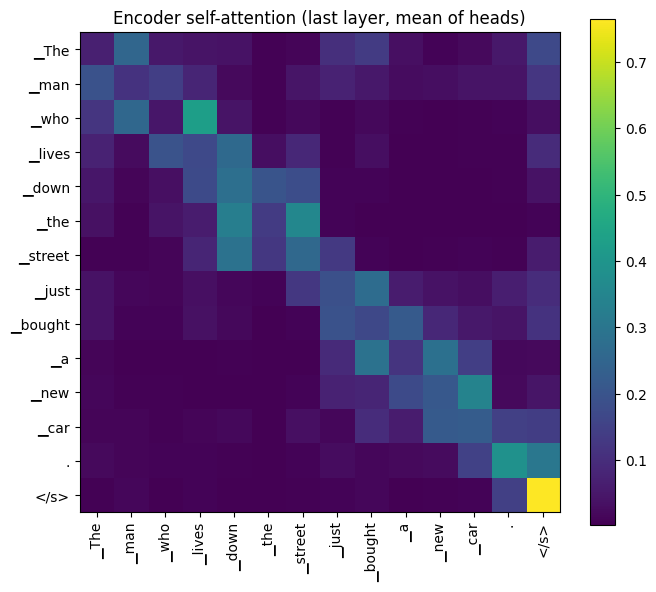

<IPython.core.display.Javascript object>

In [20]:
# quick static heatmap: last encoder layer, averaged over heads
plot_heatmap(outputs.encoder_attentions[-1][0].mean(dim=0).numpy(),
             encoder_tokens, encoder_tokens, "Encoder self-attention (last layer, mean of heads)")

# interactive view -- must be the LAST line of the cell
head_view(attention=outputs.encoder_attentions, tokens=encoder_tokens)


### 3. Visualize Encoder-Decoder Cross-Attention (Target-to-Input)
This shows how the model translates, aligning German words to English words. This is the part analogous to your LSTM's attention.

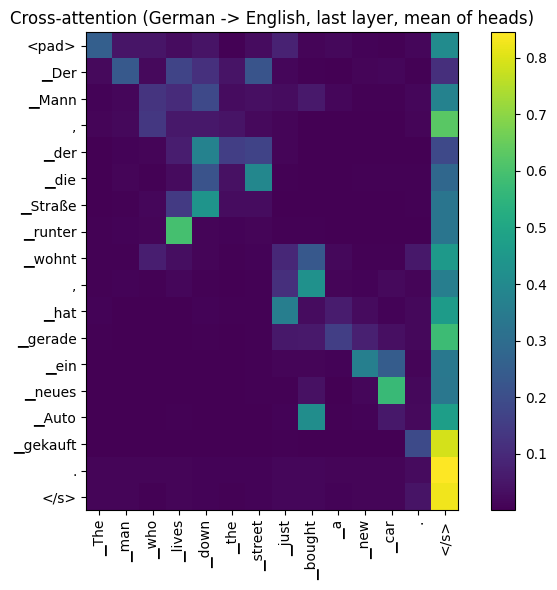

<IPython.core.display.Javascript object>

In [21]:
# quick static heatmap: last decoder layer's cross-attention, averaged over heads
# rows = German tokens, columns = English tokens
plot_heatmap(outputs.cross_attentions[-1][0].mean(dim=0).numpy(),
             encoder_tokens, decoder_tokens, "Cross-attention (German -> English, last layer, mean of heads)")

# interactive view -- choose "Cross" in the attention-type dropdown. Must be the LAST line of the cell.
head_view(encoder_attention=outputs.encoder_attentions,
          decoder_attention=outputs.decoder_attentions,
          cross_attention=outputs.cross_attentions,
          encoder_tokens=encoder_tokens,
          decoder_tokens=decoder_tokens)
